# Long-Term CO$_2$ Leakage from a Geological Storage Site: a One-Dimensional Darcy Model

__Stina K. T. Amrhein__, Institute of Structural Mechanics, Bauhaus-Universität Weimar, 99423 Weimar, Germany

__Thomas Most__, Institute of Structural Mechanics, Bauhaus-Universität Weimar, 99423 Weimar, Germany

__Christian Walther__, Institute of Structural Mechanics, Bauhaus-Universität Weimar, 99423 Weimar, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The model, the two storage sites and the input distributions are those of Amrhein, Most and Walther [[1]](https://doi.org/10.20944/preprints202609.2139.v1), "An Uncertainty Quantification Approach for Long-Term Risk Assessment of Geological CO2 Storage Sites Using a One-Dimensional Leakage Model". The text read for this notebook is the **preprint** (Preprints.org, version 1, posted 24 September 2026, not peer reviewed); no published version exists yet, and numbers in a later version may differ. Section, table and equation numbers below refer to that preprint. The model is reimplemented in numpy from the paper's equations (`co2_leakage_model.py`); the notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about ten seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import co2_leakage_model as cm

SEED = 2139                       # the only seed in this notebook (also generate_data.py's Ketzin seed)
t_start = time.perf_counter()

### Summary

Amrhein et al. [[1]](https://doi.org/10.20944/preprints202609.2139.v1) estimate how long CO$_2$ injected into a reservoir takes to leak to the ground surface, and at what rate, with a closed-form one-dimensional Darcy model of the layers above the reservoir whose 22 (Ketzin, Germany) or 30 (Quest, Canada) uncertain inputs are the layer permeabilities and depths, the injection pressure and a viscosity factor. With exact gradients at 2000 samples per site, the logarithm of the total leakage time has a dominant active direction ($\lambda_1/\lambda_2 = 5.49$ at Ketzin, 6.17 at Quest) and a two-dimensional active subspace that carries 97 % of the gradient variance and supports a cubic surrogate with leave-one-out $R^2 = 0.9859$, built almost entirely from the permeabilities of the two tightest seal layers and the viscosity. The logarithm of the minimum flow rate, smoothed here because the paper's minimum over layers has a kink, is genuinely two-dimensional ($\lambda_1/\lambda_2 = 1.44$, $\lambda_2/\lambda_3 = 21.3$), with the second direction the difference of the two seal permeabilities across which the minimum switches layers; total Sobol' indices from the reimplemented model agree with the paper's MOP sensitivity indices (largest difference 10 percentage points) and its output statistics agree within sampling error, except for one entry of its Table 5 that is inconsistent with the rest of the table.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Amrhein et al. (Sec. 2.2–2.3) model stationary, single-phase, laminar Darcy flow of CO$_2$ upward through $n$ horizontal rock layers above the reservoir. Layer $i = 1$ sits on the reservoir and layer $n$ reaches the ground; $h_i$ is the depth of the lower edge of layer $i$, with $h_{n+1} = 0$. For a unit cross-section $A = 1$ m$^2$,

$$
L_i = h_i - h_{i+1}\ \text{(Eq. 8)},\qquad
p_{total,i} = h_i\cdot 0.01\ \tfrac{\text{MPa}}{\text{m}} + p_{pump}\,\frac{h_i}{h_1}\ \text{(Eqs. 11–12)},\qquad
\Delta p_i = p_{total,i} - p_{total,i+1}\ \text{(Eq. 13)},
$$

$$
\eta_i = (\eta_{U,i} - \eta_{L,i})\,u_\eta + \eta_{L,i}\ \text{(Eq. 14)},\qquad
\dot V_i = K_i\,\frac{A\,\Delta p_i}{\eta_i L_i}\ \text{(Eq. 3)},\qquad
t_{leak,i} = \frac{\eta_i L_i^2}{K_i\,\Delta p_i}\ \text{(Eq. 5)},
$$

with $K_i$ the permeability (m$^2$), $\eta_i$ the CO$_2$ viscosity between depth-dependent bounds (Fig. 4), $p_{pump}$ the injection overpressure at the reservoir, flows in m$^3$/year and times in years (a 365-day year, as in the MATLAB listing of Table A1). The two outputs of the paper are the minimum flow rate and the total leakage time,

$$
\dot V_{min} = \min_i \dot V_i\ \text{(Eq. 6)},\qquad t_{leak,total} = \sum_{i=1}^n t_{leak,i}\ \text{(Eq. 7)}.
$$

**A simplification the paper does not state.** Because both pressures are linear in depth, $p_{total,i} = c\,h_i$ with $c = 10^4\ \text{Pa/m} + 10^6\,p_{pump}/h_1$, so $\Delta p_i = c\,L_i$ and the thickness cancels from the flow rate: $\dot V_i = K_i c/\eta_i$ and $t_{leak,i} = \eta_i L_i/(K_i c)$. The flow rates depend on the depths only through $h_1$, and the leakage times only through the thicknesses and $h_1$. The code computes the pressures as Table A1 does; the input cell below checks the cancellation numerically.

**Quantities of interest.** Both outputs are heavy-tailed (Table 5; the paper fits log-normal laws, Fig. 7), so we work with their base-10 logarithms.

1. $\log_{10} t_{leak,total}$ (years): smooth. Since $t_{leak,total} \approx (L_1 10^{-\log K_1} + L_3 10^{-\log K_3})\,\eta/c$ at Ketzin, it is a log-sum-exp, a *smooth* maximum of the two tight seal layers' times.
2. $\log_{10} \dot V_{soft}$ (m$^3$/year), with $\dot V_{soft} = \big(\sum_i \dot V_i^{-q}\big)^{-1/q}$, $q = 10$. The paper's $\dot V_{min}$ has a kink wherever two layers tie (at Ketzin, layers 1 and 3 have the same permeability range and the same viscosity, and they tie *at the median point*). The $p$-norm soft minimum is smooth and satisfies $0 \le \log_{10}\dot V_{min} - \log_{10}\dot V_{soft} \le \log_{10}(n)/q = 0.1$; on the samples the difference is at most 0.03. The exponent $q = 10$ is our choice, not the paper's. We also check the result against the exact minimum, whose gradient exists everywhere except on the ties.

Gradients of both QoIs are exact (closed form) with respect to the physical inputs.

**Inputs.** Ketzin has $n = 10$ layers and $m = 22$ independent inputs (Sec. 3.1, Table 3): $\log_{10}K_i$ symmetric triangular between the Table 3 bounds; $h_i$ uniform on the Table 3 depth $\pm 5$ m; $p_{pump}$ symmetric triangular with median 12.5 MPa and scatter $\pm 4.5$ MPa (we read "median $\pm$ scatter" as the support $[8, 17]$ MPa); $u_\eta \sim U[0, 1]$, one number for all layers. Quest (Sec. 3.2, Table 4) has $n = 14$ and $m = 30$, with $p_{pump}$ median 8.34 MPa. The table below is built from `co2_leakage_model.py` for Ketzin.

In [2]:
site = 'ketzin'
names, lo, hi = cm.names(site), *cm.bounds(site)
n_lay = cm.n_layers(site)
print(f"{'input':7s} {'units':10s} {'distribution':21s} {'support':>17s}  description")
for j, n in enumerate(names):
    print(f'{n:7s} {cm.units(site)[j]:10s} {cm.distributions(site)[j]:21s} [{lo[j]:7.2f}, {hi[j]:7.2f}]  '
          f'{cm.descriptions(site)[j]}')
s = cm.SITES[site]
print('\nviscosity bounds eta_L,i - eta_U,i (1e-3 Pa s), layers 1..10:',
      ', '.join(f'{a * 1e3:.3f}-{b * 1e3:.3f}' for a, b in zip(s['eta_lo'], s['eta_hi'])))
x0 = cm.nominal(site)
V0, t0 = cm.layers(x0, site)
print(f'\nmedian inputs (the mean parameter set of Table A1): t_total = {t0.sum():.2f} years, '
      f'V_min = {V0.min():.5f} m^3/year (layer {V0.argmin() + 1})')
print('  V_i (m^3/year):', np.array2string(V0, precision=3))
print('  t_i (years):   ', np.array2string(t0, precision=3))
c0 = cm.RHO_G + 1e6 * x0[2 * n_lay] / x0[n_lay]
eta0 = s['eta_lo'] + (s['eta_hi'] - s['eta_lo']) * x0[-1]
print(f'  max relative difference between V_i from the pressures (Eqs. 11-13) and K_i c / eta_i: '
      f'{np.max(np.abs(V0 / (10.0 ** x0[:n_lay] * c0 / eta0 * cm.SEC_PER_YEAR) - 1)):.1e}')

input   units      distribution                    support  description
logK1   log10 m^2  symmetric triangular  [ -18.00,  -16.00]  log10 permeability of layer 1 (clay stone and clay marl stone)
logK2   log10 m^2  symmetric triangular  [ -14.00,  -12.00]  log10 permeability of layer 2 (gypsum/anhydrite)
logK3   log10 m^2  symmetric triangular  [ -18.00,  -16.00]  log10 permeability of layer 3 (clay stone)
logK4   log10 m^2  symmetric triangular  [ -15.00,  -13.00]  log10 permeability of layer 4 (clay marl stone, sandstone and clay stone)
logK5   log10 m^2  symmetric triangular  [ -13.00,  -11.00]  log10 permeability of layer 5 (predominantly sandstone and siltstone)
logK6   log10 m^2  symmetric triangular  [ -14.00,  -12.00]  log10 permeability of layer 6 (clay stone, siltstone to sandstone)
logK7   log10 m^2  symmetric triangular  [ -14.00,  -12.00]  log10 permeability of layer 7 (sandstone, siltstone and clay stone)
logK8   log10 m^2  symmetric triangular  [ -17.00,  -15.00]  log10 

### Load data

`generate_data.py` drew $M = 2000$ independent samples per site by the inverse CDF (seed 2139 for Ketzin, 2140 for Quest) and wrote the physical inputs, the three outputs $t_{leak,total}$, $\dot V_{min}$, $\dot V_{soft}$, and the exact gradients of $\log_{10} t_{leak,total}$ and $\log_{10}\dot V_{soft}$ with respect to the physical inputs (see `DATA.md`). The paper used 500 improved Latin hypercube samples per site (Sec. 3.1).

In [3]:
data = {}
for st in ('ketzin', 'quest'):
    X_ = np.loadtxt(f'{st}_inputs.csv', delimiter=',')        # (M, m) physical inputs
    F_ = np.loadtxt(f'{st}_outputs.csv', delimiter=',')       # (M, 3): t_total, V_min, V_soft
    G_ = np.loadtxt(f'{st}_gradients.csv', delimiter=',')     # (M, 2m): d log10 t_total/dx, d log10 V_soft/dx
    data[st] = (X_, F_, G_)
    print(f'{st}: inputs {X_.shape}, outputs {F_.shape}, gradients {G_.shape}')
X, F, G_all = data['ketzin']
M, m = X.shape
fT, GT = np.log10(F[:, 0]), G_all[:, :m]          # QoI 1: log10 total leakage time
fV, GV = np.log10(F[:, 2]), G_all[:, m:]          # QoI 2: log10 soft-minimum flow rate

ketzin: inputs (2000, 22), outputs (2000, 3), gradients (2000, 44)
quest: inputs (2000, 30), outputs (2000, 3), gradients (2000, 60)


We check the files against the model and the exact gradients against central finite differences, and look at how far the soft minimum is from the exact one.

In [4]:
Xq, Fq, Gq = data['quest']
out_k = np.column_stack([cm.leakage_time(X, 'ketzin'), cm.min_flow(X, 'ketzin'), cm.soft_min_flow(X, 'ketzin')])
out_q = np.column_stack([cm.leakage_time(Xq, 'quest'), cm.min_flow(Xq, 'quest'), cm.soft_min_flow(Xq, 'quest')])
print(f'max relative |model - outputs.csv|: Ketzin {np.max(np.abs(out_k / F - 1)):.1e}, '
      f'Quest {np.max(np.abs(out_q / Fq - 1)):.1e}')
step = 1e-6 * (hi - lo)
fd = lambda f: np.column_stack([(f(X + step[j] * e) - f(X - step[j] * e)) / (2 * step[j])
                                for j, e in enumerate(np.eye(m))])
rel = lambda A, B: np.max(np.linalg.norm(A - B, axis=1) / np.linalg.norm(B, axis=1))
print(f'Ketzin gradients vs central differences (step 1e-6 of each range): max relative error '
      f'log10 t_total {rel(fd(lambda Z: np.log10(cm.leakage_time(Z, site))), GT):.1e}, '
      f'log10 V_soft {rel(fd(lambda Z: np.log10(cm.soft_min_flow(Z, site))), GV):.1e}')
dmin = np.log10(F[:, 1] / F[:, 2])
print(f'log10 V_min - log10 V_soft: max {dmin.max():.4f}, mean {dmin.mean():.5f} '
      f'(bound log10(10)/{cm.Q_SOFT:g} = {1 / cm.Q_SOFT:.2f}); layer attaining V_min: '
      + ', '.join(f'{i}: {c}' for i, c in enumerate(np.bincount(cm.argmin_layer(X, site))) if c))
print(f'log10 t_total in [{fT.min():.3f}, {fT.max():.3f}], sd {fT.std(ddof=1):.3f}; '
      f'log10 V_soft in [{fV.min():.3f}, {fV.max():.3f}], sd {fV.std(ddof=1):.3f}')

max relative |model - outputs.csv|: Ketzin 0.0e+00, Quest 0.0e+00
Ketzin gradients vs central differences (step 1e-6 of each range): max relative error log10 t_total 8.2e-10, log10 V_soft 8.0e-10
log10 V_min - log10 V_soft: max 0.0300, mean 0.00219 (bound log10(10)/10 = 0.10); layer attaining V_min: 1: 1020, 3: 976, 8: 4
log10 t_total in [1.768, 3.806], sd 0.348; log10 V_soft in [-1.835, 0.325], sd 0.380


### Estimate the subspace (Ketzin, total leakage time)

The model is closed-form, so we use exact gradients and the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. Every input is bounded, so the input space is `ac.Uniform` on the supports of the paper's distributions (the table above). For the uniform inputs ($h_i$, $u_\eta$) this space is exact; for the triangular ones ($\log_{10}K_i$, $p_{pump}$) it is used only for its affine map to $[-1, 1]$, and the samples keep their triangular distributions, so $\hat{\mathbf C}$ estimates the average under the paper's density. The normalized scales are therefore one decade per unit for a permeability, 5 m for a depth, 4.5 MPa for $p_{pump}$ and 0.5 for $u_\eta$. We pass physical inputs and gradients; the library applies the map once. We use 500 bootstrap replicates and the library's eigenvalue-gap rule.

In [5]:
labels = [rf'$\log K_{{{i}}}$' for i in range(1, n_lay + 1)] + \
         [rf'$h_{{{i}}}$' for i in range(1, n_lay + 1)] + [r'$p_{pump}$', r'$u_\eta$']
space = ac.Uniform(lo, hi, names=names)
sub = ac.active_subspace(space=space, X=X, f=fT, grads=GT, estimator='as', nboot=500, rng=SEED)
sub = ac.orient(sub, by='mean_gradient', grads=GT)   # sign: log10 t_total increases along w1
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
blo, bhi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues:', np.array2string(lam[:8], precision=4), '...')
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}')
print(f'95% bootstrap range: lambda_1 [{blo[0]:.4f}, {bhi[0]:.4f}], lambda_2 [{blo[1]:.4f}, {bhi[1]:.4f}], '
      f'lambda_3 [{blo[2]:.4f}, {bhi[2]:.4f}]')
print(f'share of trace: lambda_1 {lam[0] / lam.sum():.4f}, lambda_1 + lambda_2 {lam[:2].sum() / lam.sum():.4f}')

eigenvalues: [6.0065e-01 1.0931e-01 1.8737e-02 2.9456e-03 1.0334e-04 3.1714e-06
 1.8201e-06 7.6901e-07] ...
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 5.49, lambda_2/lambda_3 = 5.83, lambda_3/lambda_4 = 6.36
95% bootstrap range: lambda_1 [0.5946, 0.6067], lambda_2 [0.1039, 0.1141], lambda_3 [0.0174, 0.0199]
share of trace: lambda_1 0.8208, lambda_1 + lambda_2 0.9702


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

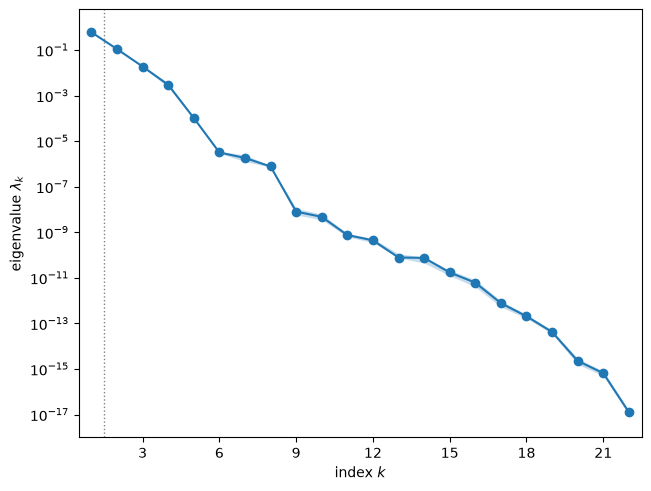

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The first eigenvalue, $\lambda_1 = 0.6006$ (95 % bootstrap range 0.5946–0.6067), is 5.49 times $\lambda_2 = 0.1093$; $\lambda_2/\lambda_3 = 5.83$ and $\lambda_3/\lambda_4 = 6.36$. $\lambda_1$ holds 82.1 % of the trace and $\lambda_1 + \lambda_2$ 97.0 %. The gap rule picks $n = 1$, but the second gap is as large as the first, so a two-dimensional subspace is the better summary; we look at both.

bootstrap mean subspace distance, k = 1..5: [0.01  0.011 0.012 0.004 0.005]


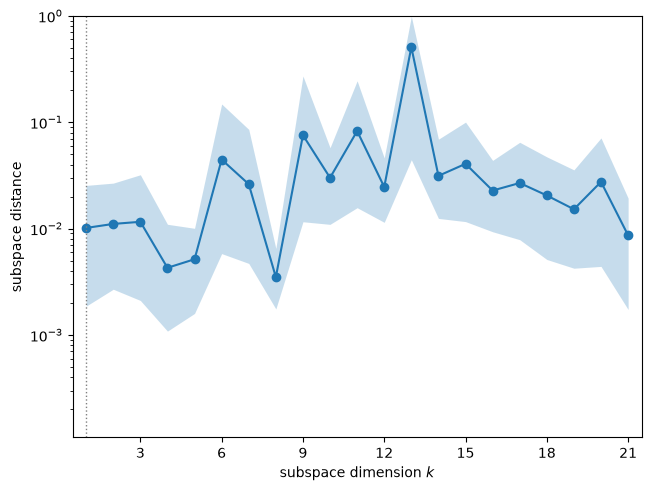

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:',
      np.array2string(sub.bootstrap_distances.mean(axis=0)[:5], precision=3))
fig

The bootstrap mean subspace distances are small for every $k$ (0.010 for $k = 1$, 0.011 for $k = 2$, 0.012 for $k = 3$): with 2000 exact gradients the leading directions are well determined.

w1: logK3 -0.748, logK1 -0.483, u_eta +0.431, p_pump -0.134, logK8 -0.049, h1 +0.021
w2: logK1 +0.803, logK3 -0.584, u_eta -0.101, h1 -0.031, h2 +0.030, p_pump +0.026
largest |w1| and |w2| component on the 10 depths: 0.031


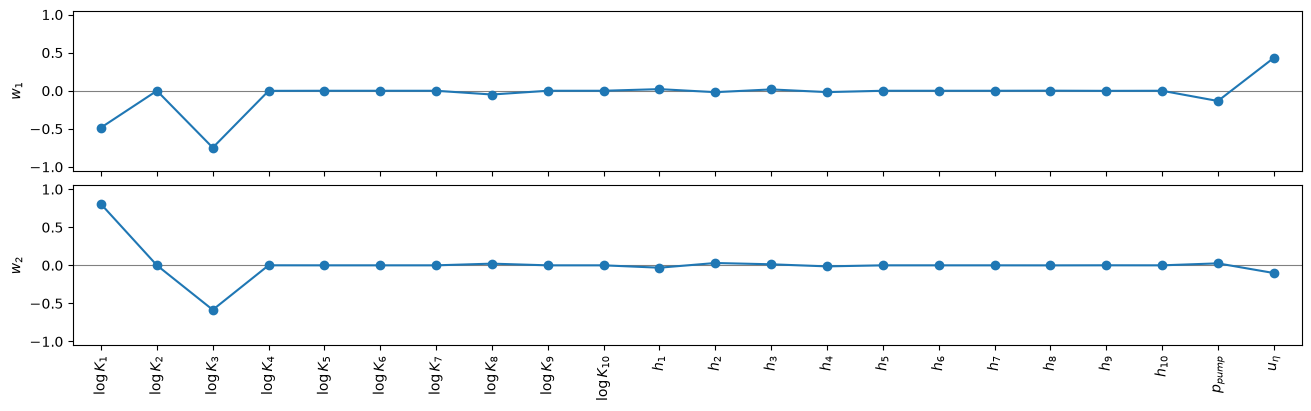

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(13, 4))
for a in np.atleast_1d(axes):
    a.tick_params(axis='x', labelrotation=90)
plt.close(fig)
top = lambda w, k=5: ', '.join(f'{names[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:k])
print('w1:', top(W[:, 0], 6))
print('w2:', top(W[:, 1], 6))
print(f'largest |w1| and |w2| component on the 10 depths: {np.abs(W[n_lay:2 * n_lay, :2]).max():.3f}')
fig

$\mathbf w_1$ is $-0.748$ on $\log K_3$, $-0.483$ on $\log K_1$, $+0.431$ on $u_\eta$ and $-0.134$ on $p_{pump}$; the next largest weight is $-0.049$ on $\log K_8$, and no depth has a weight above 0.031 in $\mathbf w_1$ or $\mathbf w_2$. The leakage time grows with the viscosity and falls with the permeabilities of the two clay-stone seals (layers 1 and 3, both $10^{-18}$–$10^{-16}$ m$^2$) and with the injection pressure. Layer 3 outweighs layer 1 because it is thicker (92 m against 57 m), so its time is larger at equal permeability. $\mathbf w_2$ is $+0.803$ on $\log K_1$ and $-0.584$ on $\log K_3$: the contrast between the two seals, which decides which of them dominates the sum of the leakage times.

y1 range [-1.33, 1.31]; corr(log10 t_total, y1) = 0.9575


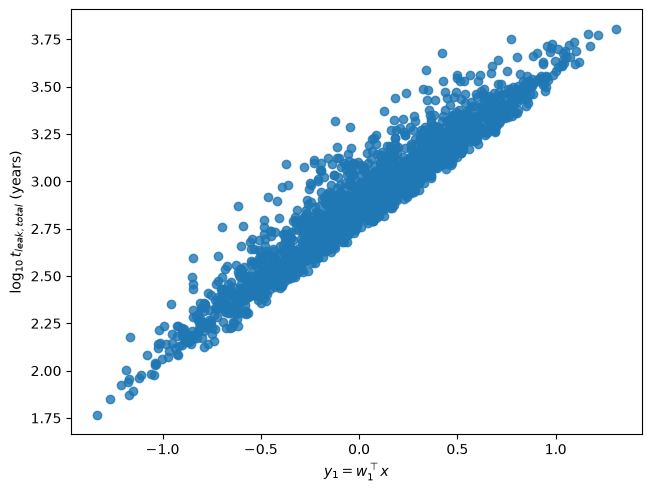

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fT, dims=1,
                                              qoi_label=r'$\log_{10} t_{leak,total}$ (years)')
plt.close(fig)
y = space.to_normalized(X) @ W[:, :2]
print(f'y1 range [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(log10 t_total, y1) = '
      f'{np.corrcoef(fT, y[:, 0])[0, 1]:.4f}')
fig

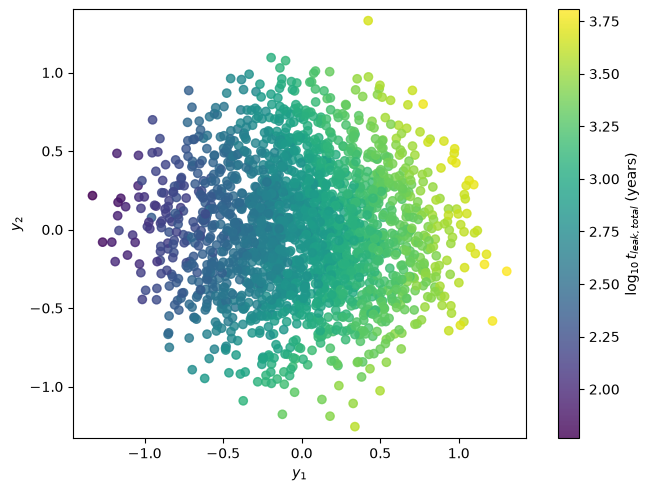

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=fT, dims=2,
                                              qoi_label=r'$\log_{10} t_{leak,total}$ (years)')
plt.close(fig)
fig

Against $y_1 = \mathbf w_1^T\mathbf x$ (range $-1.33$ to $1.31$) the log leakage time follows a clear, nearly linear trend (correlation 0.9575) with a band of moderate width. In the $(y_1, y_2)$ plot the colour changes mostly along $y_1$; the smaller change along $y_2$, the contrast between the two seals, is what the one-dimensional summary leaves out (next section).

#### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$.

LOO R^2: line in y1 0.9167; cubic in y1 0.9171; quadratic in (y1, y2) 0.9854; cubic in (y1, y2) 0.9859


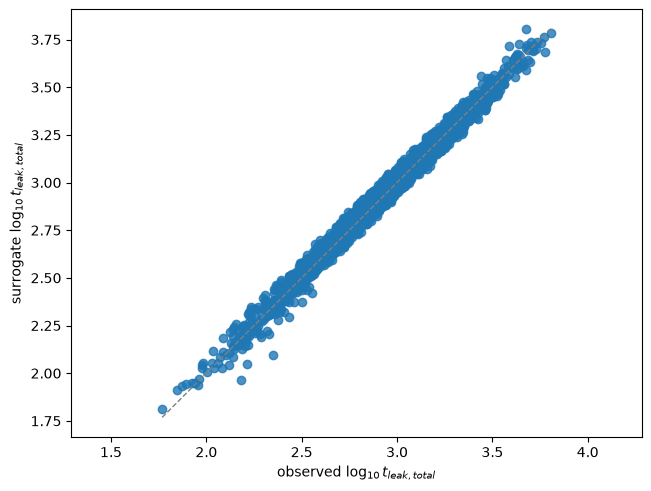

In [11]:
sub2 = ac.with_dimension(sub, 2)
sur1 = ac.fit_surrogate(X=X, f=fT, subspace=sub, kind='poly', degree=1)
sur3 = ac.fit_surrogate(X=X, f=fT, subspace=sub, kind='poly', degree=3)
sur22 = ac.fit_surrogate(X=X, f=fT, subspace=sub2, kind='poly', degree=2)
sur23 = ac.fit_surrogate(X=X, f=fT, subspace=sub2, kind='poly', degree=3)
print(f'LOO R^2: line in y1 {sur1.loo_r_squared:.4f}; cubic in y1 {sur3.loo_r_squared:.4f}; '
      f'quadratic in (y1, y2) {sur22.loo_r_squared:.4f}; cubic in (y1, y2) {sur23.loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur23, X=X, f=fT, qoi_label=r'$\log_{10} t_{leak,total}$')
plt.close(fig)
fig

A line in $y_1$ has leave-one-out $R^2 = 0.9167$, and a cubic in $y_1$ barely improves on it (0.9171), so the scatter around the one-dimensional trend is variation along $y_2$, not curvature. A quadratic in $(y_1, y_2)$ reaches 0.9854 and a cubic 0.9859, in line with $\lambda_1 + \lambda_2$ holding 97.0 % of the trace.

#### The second output: minimum flow rate (soft minimum)

The same estimator and space for $\log_{10}\dot V_{soft}$. At Ketzin the minimum is attained by layer 1 or layer 3 at 1996 of the 2000 samples (layer 8 at the other four), so up to the soft minimum $\log_{10}\dot V_{min} \approx \min(\log K_1, \log K_3) + g(p_{pump}, h_1, u_\eta)$, and $\min(a, b) = \tfrac12(a + b) - \tfrac12|a - b|$. This predicts a two-dimensional structure: one direction mixes $\log K_1 + \log K_3$ with $u_\eta$ and $p_{pump}$; the other is $\log K_1 - \log K_3$, along which $|\cdot|$ folds the function. For the exact minimum the gradient along $(\log K_1 - \log K_3)/\sqrt2$ is $\pm 1/\sqrt2$ in normalized units at almost every point, so that eigenvalue is close to 0.5. The cell also estimates the subspace from the exact minimum and its almost-everywhere gradient.

eigenvalues: [6.3028e-01 4.3826e-01 2.0568e-02 1.5747e-03 1.0343e-04 2.4130e-10] ...
n = 2; lambda_1/lambda_2 = 1.44, lambda_2/lambda_3 = 21.31, lambda_3/lambda_4 = 13.06; share of lambda_1 + lambda_2: 0.9796
w1: logK1 +0.666, logK3 +0.586, u_eta -0.443, p_pump +0.131, h1 -0.003
w2: logK3 +0.742, logK1 -0.670, u_eta -0.025, p_pump +0.007, logK8 -0.000


exact min: lambda_1, lambda_2, lambda_3 = 0.6311, 0.4978, 0.0206; lambda_1/lambda_2 = 1.27, lambda_2/lambda_3 = 24.18; distance between the 2-D subspaces of V_soft and V_min: 0.0007
LOO R^2, degree-2 polynomial in (y1, y2): 0.9701
LOO R^2, degree-4 polynomial in (y1, y2): 0.9821
LOO R^2, cubic in y1 alone: 0.7981


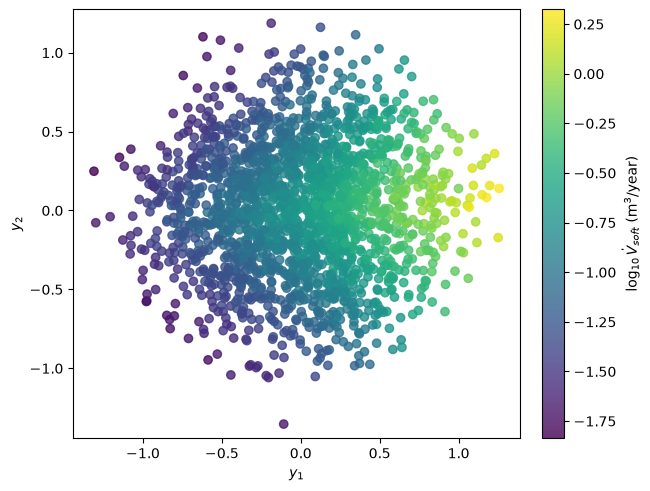

In [12]:
sub_v = ac.active_subspace(space=space, X=X, f=fV, grads=GV, estimator='as', nboot=500, rng=SEED)
sub_v = ac.orient(sub_v, by='mean_gradient', grads=GV)
lv, Wv = sub_v.eigenvalues, sub_v.eigenvectors
print('eigenvalues:', np.array2string(lv[:6], precision=4), '...')
print(f'n = {sub_v.n}; lambda_1/lambda_2 = {lv[0] / lv[1]:.2f}, lambda_2/lambda_3 = {lv[1] / lv[2]:.2f}, '
      f'lambda_3/lambda_4 = {lv[2] / lv[3]:.2f}; share of lambda_1 + lambda_2: {lv[:2].sum() / lv.sum():.4f}')
print('w1:', top(Wv[:, 0], 5))
print('w2:', top(Wv[:, 1], 5))
# the exact minimum, with its gradient where it exists (one layer attains the minimum)
G_min = cm.grad_log10_min_flow(X, site)
sub_min = ac.active_subspace(space=space, X=X, f=np.log10(F[:, 1]), grads=G_min, estimator='as', nboot=200,
                             rng=SEED)
lm = sub_min.eigenvalues
P = lambda A: A[:, :2] @ A[:, :2].T
print(f'exact min: lambda_1, lambda_2, lambda_3 = {lm[0]:.4f}, {lm[1]:.4f}, {lm[2]:.4f}; lambda_1/lambda_2 = {lm[0] / lm[1]:.2f}, lambda_2/lambda_3 = {lm[1] / lm[2]:.2f}; '
      f'distance between the 2-D subspaces of V_soft and V_min: {np.linalg.norm(P(Wv) - P(sub_min.eigenvectors), 2):.4f}')
sv2 = ac.with_dimension(sub_v, 2)
for deg in (2, 4):
    print(f'LOO R^2, degree-{deg} polynomial in (y1, y2): '
          f'{ac.fit_surrogate(X=X, f=fV, subspace=sv2, kind="poly", degree=deg).loo_r_squared:.4f}')
print(f'LOO R^2, cubic in y1 alone: '
      f'{ac.fit_surrogate(X=X, f=fV, subspace=ac.with_dimension(sub_v, 1), kind="poly", degree=3).loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(sv2, X=X, f=fV, dims=2,
                                              qoi_label=r'$\log_{10} \dot V_{soft}$ (m$^3$/year)')
plt.close(fig)
fig

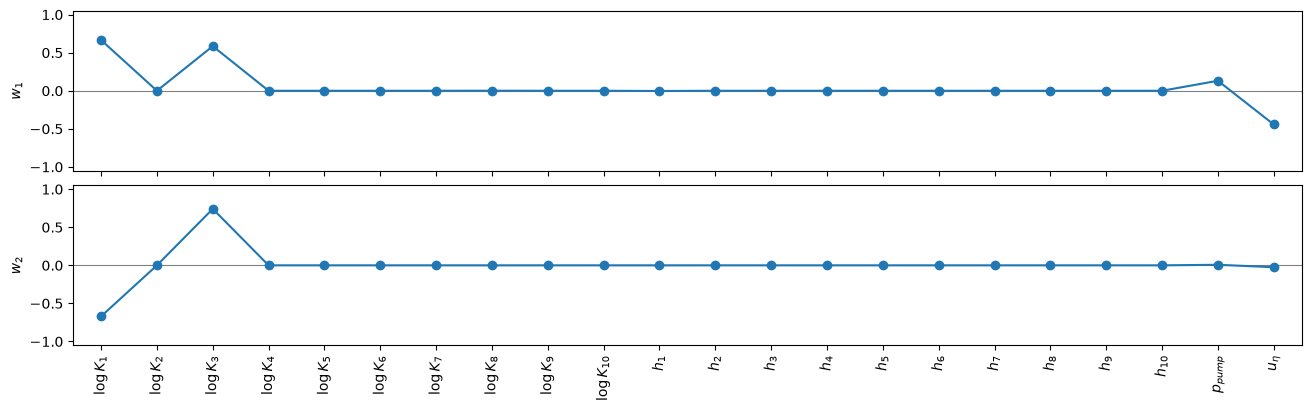

In [13]:
fig, axes = ac.plotting.plot_eigenvectors(sub_v, indices=[0, 1], labels=labels, figsize=(13, 4))
for a in np.atleast_1d(axes):
    a.tick_params(axis='x', labelrotation=90)
plt.close(fig)
fig

The eigenvalues confirm the prediction: $\lambda_1 = 0.6303$ and $\lambda_2 = 0.4383$ are close ($\lambda_1/\lambda_2 = 1.44$), then a gap of 21.31 to $\lambda_3$, and the first two hold 98.0 % of the trace. $\mathbf w_1$ is $+0.666$ on $\log K_1$, $+0.586$ on $\log K_3$, $-0.443$ on $u_\eta$ and $+0.131$ on $p_{pump}$; $\mathbf w_2$ is $+0.742$ on $\log K_3$ and $-0.670$ on $\log K_1$, the fold direction. The two-dimensional summary plot shows the fold: at fixed $y_1$ the flow rate is largest at $y_2 = 0$, where the seals are equally tight, and falls on both sides. The exact minimum gives $\lambda_2 = 0.4978$, as predicted, with $\lambda_1/\lambda_2 = 1.27$ and $\lambda_2/\lambda_3 = 24.18$, and its two-dimensional subspace is 0.0007 from that of the soft minimum, so the smoothing changes the eigenvalues slightly (it lowers the fold eigenvalue from about 0.5) but not the subspace. A cubic in $y_1$ alone has leave-one-out $R^2 = 0.7981$; a quadratic in $(y_1, y_2)$ 0.9701, and a quartic 0.9821, which captures more of the fold.

#### The Quest site

The same analysis for Quest ($m = 30$; Table 4, Sec. 3.2), for both outputs, in `ac.Uniform` on the supports of its distributions. Its tight layers are the two Lotsberg salt seals (layers 3 and 5, $10^{-19}$–$10^{-17}$ m$^2$), with the shale and evaporite seals (layers 1 and 7, $10^{-18}$–$10^{-16}$ m$^2$) next.

Quest log10 t_total: eigenvalues [4.6237e-01 7.4906e-02 1.0588e-02 3.4632e-03 3.6399e-04] ...; n = 1; lambda_1/lambda_2 = 6.17, lambda_2/lambda_3 = 7.07; share of lambda_1 + lambda_2 0.9738
   w1: logK5 -0.898, logK3 -0.368, u_eta +0.175, logK7 -0.113, p_pump -0.094
   w2: logK3 +0.902, logK5 -0.405, logK7 +0.080, u_eta -0.075, h3 -0.055
   LOO R^2: cubic in y1 0.9153, cubic in (y1, y2) 0.9864


Quest log10 V_soft: eigenvalues [5.0915e-01 4.2838e-01 7.9229e-03 6.3786e-03 3.6393e-04] ...; n = 2; lambda_1/lambda_2 = 1.19, lambda_2/lambda_3 = 54.07; share of lambda_1 + lambda_2 0.9846
   w1: logK5 +0.801, logK3 +0.567, u_eta -0.167, p_pump +0.090, logK7 +0.004
   w2: logK3 +0.812, logK5 -0.582, u_eta -0.028, p_pump +0.015, logK7 +0.001
   LOO R^2: cubic in y1 0.7531, cubic in (y1, y2) 0.9750


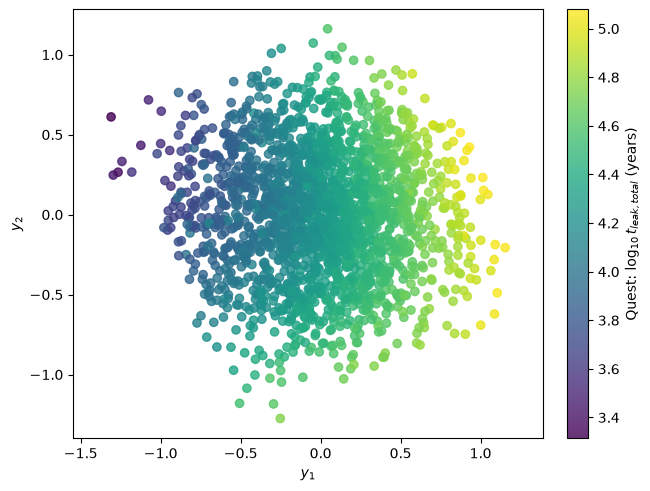

In [14]:
Xq, Fq, Gq = data['quest']
mq = Xq.shape[1]
names_q, lo_q, hi_q = cm.names('quest'), *cm.bounds('quest')
space_q = ac.Uniform(lo_q, hi_q, names=names_q)
res_q = {}
for lab, f_, G_ in [('log10 t_total', np.log10(Fq[:, 0]), Gq[:, :mq]), ('log10 V_soft', np.log10(Fq[:, 2]), Gq[:, mq:])]:
    s_ = ac.active_subspace(space=space_q, X=Xq, f=f_, grads=G_, estimator='as', nboot=500, rng=SEED)
    s_ = ac.orient(s_, by='mean_gradient', grads=G_)
    l_, W_ = s_.eigenvalues, s_.eigenvectors
    r1 = ac.fit_surrogate(X=Xq, f=f_, subspace=ac.with_dimension(s_, 1), kind='poly', degree=3).loo_r_squared
    r2 = ac.fit_surrogate(X=Xq, f=f_, subspace=ac.with_dimension(s_, 2), kind='poly', degree=3).loo_r_squared
    res_q[lab] = (s_, f_)
    print(f'Quest {lab}: eigenvalues {np.array2string(l_[:5], precision=4)} ...; n = {s_.n}; '
          f'lambda_1/lambda_2 = {l_[0] / l_[1]:.2f}, lambda_2/lambda_3 = {l_[1] / l_[2]:.2f}; '
          f'share of lambda_1 + lambda_2 {l_[:2].sum() / l_.sum():.4f}')
    print('   w1:', ', '.join(f'{names_q[i]} {W_[i, 0]:+.3f}' for i in np.argsort(-np.abs(W_[:, 0]))[:5]))
    print('   w2:', ', '.join(f'{names_q[i]} {W_[i, 1]:+.3f}' for i in np.argsort(-np.abs(W_[:, 1]))[:5]))
    print(f'   LOO R^2: cubic in y1 {r1:.4f}, cubic in (y1, y2) {r2:.4f}')
s_qT, f_qT = res_q['log10 t_total']
fig, ax = ac.plotting.plot_sufficient_summary(s_qT, X=Xq, f=f_qT, dims=2,
                                              qoi_label=r'Quest: $\log_{10} t_{leak,total}$ (years)')
plt.close(fig)
fig

Quest repeats the Ketzin pattern. For $\log_{10} t_{leak,total}$, $\lambda_1/\lambda_2 = 6.17$ and $\lambda_2/\lambda_3 = 7.07$, with 97.4 % of the trace in two dimensions; $\mathbf w_1$ is $-0.898$ on $\log K_5$, $-0.368$ on $\log K_3$, $+0.175$ on $u_\eta$, $-0.113$ on $\log K_7$ and $-0.094$ on $p_{pump}$. The upper salt layer 5 dominates because it is 85 m thick against 35 m for layer 3, and viscosity matters less than at Ketzin because the deep layers' viscosity range (0.040–0.070 $\times10^{-3}$ Pa s) is narrower relative to its values. A cubic in $y_1$ has leave-one-out $R^2 = 0.9153$ and a cubic in $(y_1, y_2)$ 0.9864. For $\log_{10}\dot V_{soft}$, $\lambda_1/\lambda_2 = 1.19$ and $\lambda_2/\lambda_3 = 54.07$ (98.5 % of the trace in two dimensions), with $\mathbf w_2$ the fold direction $\log K_3 - \log K_5$ ($+0.812$, $-0.582$); a cubic in $y_1$ gives 0.7531, a cubic in $(y_1, y_2)$ 0.9750. In the plot above, the colour of the log leakage time changes mostly along $y_1$.

### Comparison with the paper

The paper reports no active subspace. It reports sample statistics of the outputs from 500 Latin hypercube samples (Table 5 for Ketzin, Table 6 for Quest) and "Coefficients of Prognosis" from the Metamodel of Optimal Prognosis (MOP) in Ansys optiSLang, a variance-based total-effect measure, for the raw outputs $\dot V_{min}$ and $t_{leak}$ (Fig. 7g–h, Ketzin; Fig. 9g–h, Quest; values read from the bar labels). We compare the statistics with ours from 2000 samples, and the MOP indices with total Sobol' indices of the raw outputs computed from the reimplemented model with Jansen's estimator ([[3]](https://doi.org/10.1016/j.cpc.2009.09.018); $N = 20\,000$ base samples, seed 2139).

In [15]:
def stats(a):
    return np.array([a.min(), a.max(), a.mean(), a.std(ddof=1), np.quantile(a, 0.05), np.quantile(a, 0.95)])

Vk, tk = cm.layers(X, 'ketzin')
Vq, tq = cm.layers(Xq, 'quest')
rows = [  # (label, paper Table 5/6: min, max, mean, sd, 5 %, 95 %), our samples
    ('Ketzin V_3', [0.016, 3.726, 0.401, 0.448, 0.040, 1.225], Vk[:, 2]),
    ('Ketzin V_1', [0.017, 4.384, 0.412, 0.497, 0.045, 1.369], Vk[:, 0]),
    ('Ketzin V_min', [0.016, 2.166, 0.214, 0.222, 0.032, 0.681], F[:, 1]),
    ('Ketzin t_3', [24.2, 5605.2, 643.4, 786.42, 73.1, 2283.0], tk[:, 2]),
    ('Ketzin t_1', [13.3, 3171.9, 394.5, 455.2, 42.2, 1249.0], tk[:, 0]),
    ('Ketzin t_total', [68.2, 6206.2, 1063.0, 962.0, 209.3, 2248.8], F[:, 0]),
    ('Quest V_min', [0.001, 0.057, 0.006, 0.006, 0.001, 0.017], Fq[:, 1]),
    ('Quest t_5', [1082.2, 104252, 16348.5, 16389.4, 2233.4, 51908.3], tq[:, 4]),
    ('Quest t_3', [433.9, 48809.5, 6846.8, 7480.1, 870.3, 22911.4], tq[:, 2]),
    ('Quest t_total', [2717.9, 108208, 25711.5, 18337.3, 7198.4, 64170.4], Fq[:, 0])]
print(f"{'output':15s} {'':6s} {'min':>10s} {'max':>10s} {'mean':>10s} {'sd':>10s} {'5%':>10s} {'95%':>10s}")
for lab, pap, a in rows:
    print(f'{lab:15s} {"paper":6s} ' + ' '.join(f'{v:10.6g}' for v in pap))
    print(f'{"":15s} {"here":6s} ' + ' '.join(f'{v:10.5g}' for v in stats(a)))
q95_t3 = np.quantile(tk[:, 2], 0.95)
print(f'\nKetzin: t_total >= t_3 at every sample ({np.all(F[:, 0] >= tk[:, 2])}), so q95(t_total) >= q95(t_3): '
      f'here {np.quantile(F[:, 0], 0.95):.1f} >= {q95_t3:.1f}; Table 5 gives 2248.8 < 2283.0')

output                        min        max       mean         sd         5%        95%
Ketzin V_3      paper       0.016      3.726      0.401      0.448       0.04      1.225
                here     0.017543     4.1105    0.40879    0.50472   0.045217     1.3973
Ketzin V_1      paper       0.017      4.384      0.412      0.497      0.045      1.369
                here     0.014627     4.2152    0.39339     0.4574   0.044383      1.324
Ketzin V_min    paper       0.016      2.166      0.214      0.222      0.032      0.681
                here     0.014627      2.156    0.20875    0.22688   0.035005     0.6491
Ketzin t_3      paper        24.2     5605.2      643.4     786.42       73.1       2283
                here       22.103     5486.5      639.8     712.91     65.352     2042.1
Ketzin t_1      paper        13.3     3171.9      394.5      455.2       42.2       1249
                here       12.996     3754.7     396.36      440.8     43.348     1300.2
Ketzin t_total  paper

The statistics agree within the sampling error of 500 samples for every row except one: where the tables give three or more significant digits the means differ by at most 4.5 % (Ketzin $\dot V_1$, 0.39339 against 0.412, about one standard error of a 500-sample mean), and the total leakage times agree closely (Ketzin 1061.8 years here, 1063.0 in Table 5; Quest 25 350 against 25 711.5), and the 5 % quantiles that the paper uses for its safety statements are 203.6 against 209.3 years (Ketzin) and 6913 against 7198.4 years (Quest). The exception is the 95 % quantile of the Ketzin total leakage time: Table 5 gives 2248.8 years, which is *smaller* than its own 95 % quantile of the layer-3 time, 2283.0 years, although $t_{leak,total} \ge t_{leak,3}$ at every sample; our value is 2882.6 years. A log-normal law with Table 5's mean and standard deviation has a 95 % quantile near 2800 years, so the table entry looks like a typo or a value from a different estimator. The extremes differ more, as they should with 2000 against 500 samples.

In [16]:
def total_indices(fun, st, N, rng):
    """Jansen's estimator of the total-effect Sobol' indices of fun(X, st), from 2 N base samples."""
    A, B = cm.sample(N, rng, st), cm.sample(N, rng, st)
    fA, fB = fun(A, st), fun(B, st)
    D = np.var(np.r_[fA, fB])
    ST = np.empty(A.shape[1])
    for j in range(A.shape[1]):
        ABj = A.copy()
        ABj[:, j] = B[:, j]
        ST[j] = 0.5 * np.mean((fA - fun(ABj, st)) ** 2) / D
    return ST

rng = np.random.default_rng(SEED)
paper_cop = {  # Coefficients of Prognosis (MOP), Fig. 7g-h (Ketzin) and Fig. 9g-h (Quest), in %
    ('ketzin', 'V_min'): dict(logK1=53, logK3=52, u_eta=30, p_pump=3),
    ('ketzin', 't_total'): dict(logK3=59, u_eta=33, logK1=19, p_pump=3, logK8=1, h3=0),
    ('quest', 'V_min'): dict(logK5=60, logK3=57, u_eta=3, p_pump=1),
    ('quest', 't_total'): dict(logK5=79, logK3=15, u_eta=6, logK7=1, p_pump=1, h4=1)}
for (st, out), cop in paper_cop.items():
    fun = cm.min_flow if out == 'V_min' else cm.leakage_time
    ST = total_indices(fun, st, 20000, rng)
    nm = cm.names(st)
    print(f'{st:6s} {out:7s} paper CoP / total Sobol index here (%): '
          + ', '.join(f'{k} {v}/{100 * ST[nm.index(k)]:.1f}' for k, v in cop.items())
          + f'; largest other: {max((100 * ST[i], nm[i]) for i in range(len(nm)) if nm[i] not in cop)[1]} '
          + f'{max(100 * ST[i] for i in range(len(nm)) if nm[i] not in cop):.1f}')
alpha = ac.activity_scores(sub2)
print('\nKetzin log10 t_total, activity scores (n = 2), top five:',
      ', '.join(f'{names[i]} {alpha[i]:.4f}' for i in np.argsort(-alpha)[:5]))

ketzin V_min   paper CoP / total Sobol index here (%): logK1 53/53.3, logK3 52/50.0, u_eta 30/32.4, p_pump 3/1.7; largest other: logK8 0.4
ketzin t_total paper CoP / total Sobol index here (%): logK3 59/56.0, u_eta 33/28.9, logK1 19/21.4, p_pump 3/2.4, logK8 1/0.1, h3 0/0.1; largest other: h1 0.1


quest  V_min   paper CoP / total Sobol index here (%): logK5 60/61.8, logK3 57/67.3, u_eta 3/6.0, p_pump 1/0.9; largest other: logK1 2.0


quest  t_total paper CoP / total Sobol index here (%): logK5 79/80.2, logK3 15/13.1, u_eta 6/7.1, logK7 1/0.8, p_pump 1/1.1, h4 1/0.2; largest other: logK1 0.2

Ketzin log10 t_total, activity scores (n = 2), top five: logK3 0.3730, logK1 0.2107, u_eta 0.1128, p_pump 0.0109, logK8 0.0015


| Quantity | Paper value | Notebook value |
|---|---|---|
| Ketzin $t_{leak,total}$: mean, sd, 5 %, 95 % (years) | 1063.0, 962.0, 209.3, 2248.8 [Table 5] | 1061.8, 886.3, 203.59, 2882.6 |
| Ketzin $\dot V_{min}$: mean, sd, 5 %, 95 % (m$^3$/year) | 0.214, 0.222, 0.032, 0.681 [Table 5] | 0.20875, 0.22688, 0.035005, 0.6491 |
| Quest $t_{leak,total}$: mean, sd, 5 %, 95 % (years) | 25711.5, 18337.3, 7198.4, 64170.4 [Table 6] | 25350, 18252, 6912.8, 61817 |
| Quest $\dot V_{min}$: mean, sd, 5 %, 95 % (m$^3$/year) | 0.006, 0.006, 0.001, 0.017 [Table 6] | 0.0065361, 0.0059648, 0.0013638, 0.017866 |
| Ketzin $\dot V_{min}$, total effect of $\log K_1$, $\log K_3$, $u_\eta$, $p_{pump}$ (%) | 53, 52, 30, 3 (MOP CoP, Fig. 7g) | 53.3, 50.0, 32.4, 1.7 (total Sobol') |
| Ketzin $t_{leak}$, total effect of $\log K_3$, $u_\eta$, $\log K_1$, $p_{pump}$, $\log K_8$ (%) | 59, 33, 19, 3, 1 (Fig. 7h) | 56.0, 28.9, 21.4, 2.4, 0.1 |
| Quest $\dot V_{min}$, total effect of $\log K_5$, $\log K_3$, $u_\eta$, $p_{pump}$ (%) | 60, 57, 3, 1 (Fig. 9g) | 61.8, 67.3, 6.0, 0.9 |
| Quest $t_{leak}$, total effect of $\log K_5$, $\log K_3$, $u_\eta$, $\log K_7$, $p_{pump}$ (%) | 79, 15, 6, 1, 1 (Fig. 9h) | 80.2, 13.1, 7.1, 0.8, 1.1 |
| Most important inputs (text, Sec. 3.1, 3.2) | Ketzin: $K_1$, $K_3$, viscosity; minor $K_8$, $p_{pump}$. Quest: $K_3$, $K_5$; minor viscosity, $p_{pump}$, $K_7$ | Ketzin $\lvert\mathbf w_1\rvert$ ($\log t$): $\log K_3$, $\log K_1$, $u_\eta$, $p_{pump}$, $\log K_8$. Quest: $\log K_5$, $\log K_3$, $u_\eta$, $\log K_7$, $p_{pump}$ |
| Active subspace, $\log_{10} t_{leak,total}$ | not reported | Ketzin $\lambda_1/\lambda_2 = 5.49$, $\lambda_2/\lambda_3 = 5.83$; cubic in $(y_1, y_2)$: LOO $R^2 = 0.9859$. Quest 6.17, 7.07; 0.9864 |
| Active subspace, $\log_{10}\dot V_{soft}$ | not reported | Ketzin $\lambda_1/\lambda_2 = 1.44$, $\lambda_2/\lambda_3 = 21.31$; Quest 1.19, 54.07 |

**Reimplementation.** The paper's model ran in MS Excel, and its statistics come from 500 improved Latin hypercube samples whose seed is not given, so we cannot reproduce its numbers exactly; the agreement of the statistics within sampling error, and of the total-effect indices within a few percentage points (the largest difference is $\log K_3$ for the Quest minimum flow, 57 against 67.3; MOP indices come from a metamodel fitted to 500 samples, and our Jansen estimates carry Monte Carlo error of their own), is the evidence that `co2_leakage_model.py` is the paper's model. The total-effect indices and the eigenvectors agree on what matters: the permeabilities of the two tightest seal layers, then the viscosity factor, then the injection pressure; the eleven to fifteen other layers and all the depths hardly matter (activity scores for $\log_{10} t_{leak,total}$ at Ketzin with $n = 2$: $\log K_3$ 0.3730, $\log K_1$ 0.2107, $u_\eta$ 0.1128, $p_{pump}$ 0.0109, $\log K_8$ 0.0015 [[4]](https://doi.org/10.1016/j.ress.2017.01.013)).

**What the active subspace adds.** The sensitivity indices say *which* inputs matter; the active subspace says *how they combine*. For the leakage time, one combination of the two seal permeabilities and the viscosity (weighted toward the thicker seal) explains most of the variation, and the second direction is the contrast between the seals. For the minimum flow rate, the two seals enter through their minimum, so the function is folded along their difference and no single direction suffices. That explains why the paper's indices for $\dot V_{min}$ have two nearly equal permeability terms whose total effects sum to more than 100 %.

### References

[1] S. K. T. Amrhein, T. Most, and C. Walther. [An Uncertainty Quantification Approach for Long-Term Risk Assessment of Geological CO2 Storage Sites Using a One-Dimensional Leakage Model](https://doi.org/10.20944/preprints202609.2139.v1). Preprints.org, 2026 (version 1, not peer reviewed; no published version yet).

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications*, 181(2):259–270, 2010.

[4] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[R1]: https://doi.org/10.20944/preprints202609.2139.v1
[R3]: https://doi.org/10.1016/j.cpc.2009.09.018
[R4]: https://doi.org/10.1016/j.ress.2017.01.013

### Acknowledgments

From [[1]][R1]: "This work was partially funded by the Free State of Thuringia (Germany) under the grant “2024 VFE 0077” using funds from the European Regional Development Fund (ERDF)."

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 8.4 s
